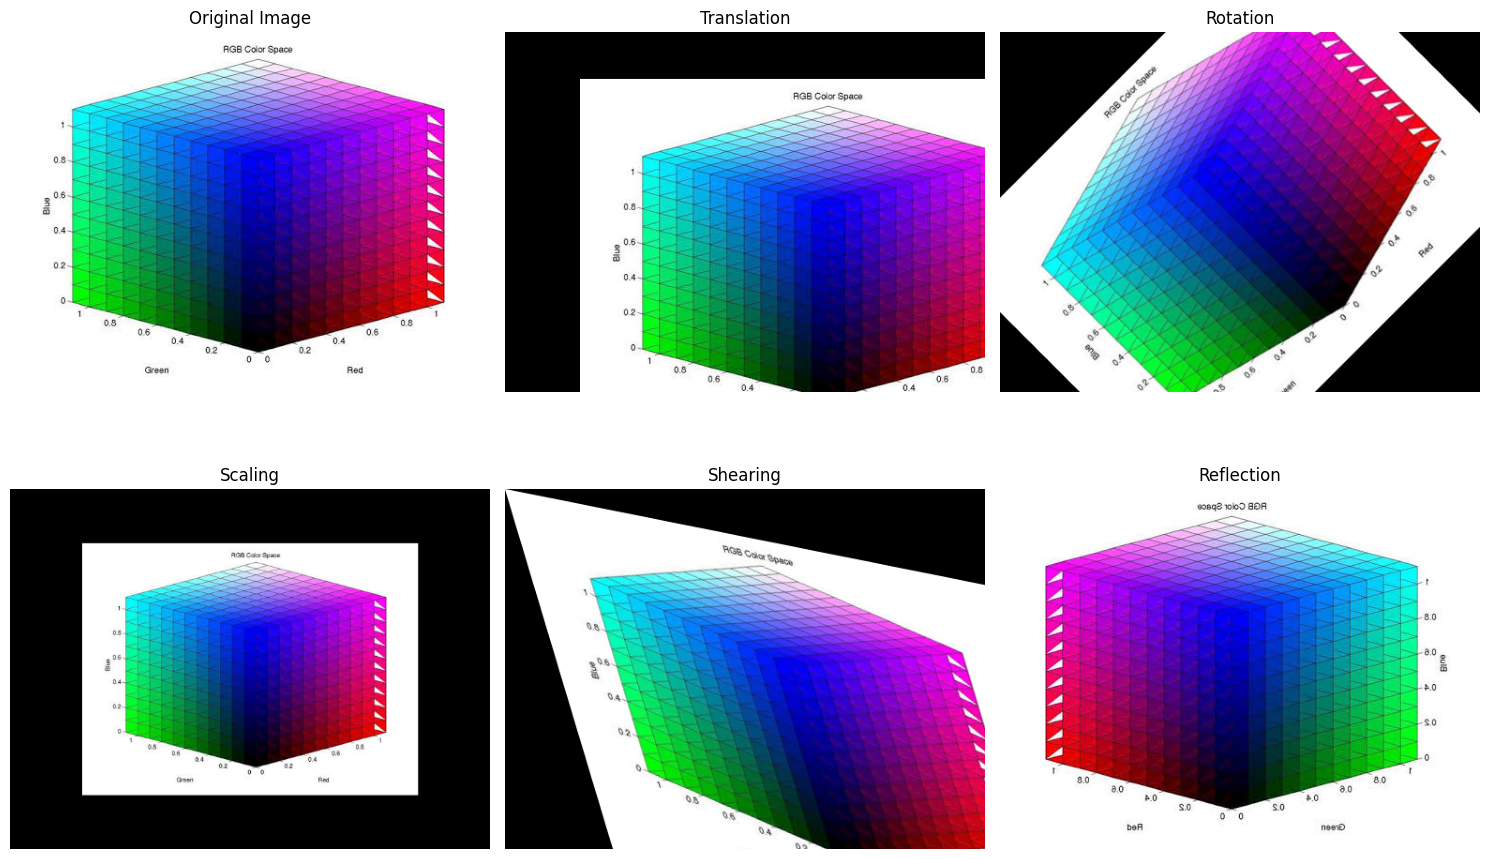

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the image from the workspace and convert it to RGB
img_bgr = cv2.imread('/content/images.jfif')
if img_bgr is None:
    raise FileNotFoundError("Could not load /content/images.jfif. Please make sure the file exists and is a valid image.")
img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

h, w = img.shape[:2]

# 1. Translation
T = np.float32([[1, 0, 80],
                [0, 1, 50]])
translation = cv2.warpAffine(img, T, (w, h))

# 2. Rotation
center = (w // 2, h // 2)
R = cv2.getRotationMatrix2D(center, 45, 1)
rotation = cv2.warpAffine(img, R, (w, h))

# 3. Scaling
S = cv2.getRotationMatrix2D(center, 0, 0.7)
scaling = cv2.warpAffine(img, S, (w, h))

# 4. Shearing
SH = np.float32([[1, 0.3, 0],
                 [0.2, 1, 0]])
shearing = cv2.warpAffine(img, SH, (w, h))

# 5. Reflection (Horizontal)
reflection = cv2.flip(img, 1)

# Display Results
titles = ['Original Image', 'Translation',
          'Rotation', 'Scaling',
          'Shearing', 'Reflection']

images = [img, translation, rotation,
          scaling, shearing, reflection]

plt.figure(figsize=(15, 10))

for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i])
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

# Save images
for title, image in zip(titles[1:], images[1:]):
    cv2.imwrite(title.lower() + '.png',
                cv2.cvtColor(image, cv2.COLOR_RGB2BGR))